# Extracting and Visualizing Stock Data: Tesla & GameStop
**IBM Python Project for Data Science — Peer-Graded Final Assignment**

This Jupyter notebook extracts historical stock data using `yfinance`, extracts quarterly revenue from HTML using `requests` and `BeautifulSoup`, and compares stock prices with revenue in two dashboards.

**Data provenance / reproducibility:** The notebook attempts the online extraction first. If the external service cannot be reached, the published historical snapshots in the companion `data/` folder are used. The snapshot stock CSVs were originally obtained from yfinance; the quarterly revenue snapshots were sourced from the public repository linked below. Offline extraction is always marked in the notebook output rather than presented as a successful live request.

Data snapshots: https://github.com/filipe-braiman/stock-data-extraction-visualization/tree/master/Datasets

The sources are historical snapshots through 2025, not live November 2026 market data.

In [1]:
from pathlib import Path
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

try:
    import yfinance as yf
except ImportError:
    yf = None  # Offline: historical yfinance CSV snapshots are included in data/.

DATA_DIR = Path("data")
assert DATA_DIR.exists(), "Unzip the complete project before running this notebook."
plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "figure.dpi": 115})

## Question 1: Use yfinance to Extract Tesla Stock Data
Create the Tesla ticker, request its full trading history, reset the index, and show the first five rows.

In [2]:
# Question 1 — Tesla (TSLA): yfinance stock history
if yf is not None:
    try:
        tesla = yf.Ticker("TSLA")
        tesla_data = tesla.history(period="max")
        if tesla_data.empty:
            raise ValueError("yfinance returned no Tesla rows")
        tesla_data.reset_index(inplace=True)
        tesla_source = "Live yfinance query"
    except Exception as exc:
        tesla_data = pd.read_csv(DATA_DIR / "tesla_data.csv")
        tesla_source = "Archived yfinance CSV snapshot (offline fallback)"
else:
    tesla_data = pd.read_csv(DATA_DIR / "tesla_data.csv")
    tesla_source = "Archived yfinance CSV snapshot (offline fallback)"

print("Source:", tesla_source)
display(tesla_data.head())

Source: Archived yfinance CSV snapshot (offline fallback)


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


## Question 2: Use Webscraping to Extract Tesla Revenue Data
Download the quarterly revenue table, parse HTML with BeautifulSoup, remove currency punctuation, and show the last five rows.

In [3]:
# HTML table parser reused for questions 2 and 4
# The quarterly revenue values use USD millions.
def parse_quarterly_revenue(html_text):
    soup = BeautifulSoup(html_text, "html.parser")
    tables = soup.find_all("table")
    candidates = []
    for table in tables:
        rows = []
        for tr in table.find_all("tr"):
            cols = tr.find_all("td")
            if len(cols) < 2:
                continue
            date_text = cols[0].get_text(" ", strip=True)
            money = cols[1].get_text(" ", strip=True).replace("$", "").replace(",", "")
            if money and pd.notna(pd.to_numeric(money, errors="coerce")):
                try:
                    pd.to_datetime(date_text, errors="raise")
                    rows.append((date_text, money))
                except (ValueError, TypeError):
                    pass
        if len(rows) >= 5:
            candidates.append(rows)
    if not candidates:
        raise ValueError("Could not find a quarterly revenue table")
    df = pd.DataFrame(candidates[-1], columns=["Date", "Revenue"])
    df["Date"] = pd.to_datetime(df["Date"]).dt.strftime("%Y-%m-%d")
    df["Revenue"] = df["Revenue"].astype(int)
    df = df.dropna().reset_index(drop=True)
    return df

def revenue_from_web_or_snapshot(url, snapshot_html):
    try:
        response = requests.get(url, timeout=8, headers={"User-Agent": "Mozilla/5.0"})
        response.raise_for_status()
        result = parse_quarterly_revenue(response.text)
        return result, "Live web scraping: " + url
    except (requests.RequestException, ValueError, KeyError) as exc:
        # This is an explicitly identified *offline HTML mirror* of public revenue rows.
        html_data = Path(snapshot_html).read_text(encoding="utf-8")
        return parse_quarterly_revenue(html_data), "Archived HTML revenue table (offline fallback)"

In [4]:
# Question 2 — Tesla quarterly revenue using requests + BeautifulSoup
url = ("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
       "IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/tesla.html")
tesla_revenue, tesla_revenue_source = revenue_from_web_or_snapshot(
    url, DATA_DIR / "tesla_revenue_snapshot.html"
)
print("Source:", tesla_revenue_source)
display(tesla_revenue.tail())

Source: Archived HTML revenue table (offline fallback)


,Date,Revenue
54,2011-12-31,39
55,2011-09-30,58
56,2011-06-30,58
57,2011-03-31,49
58,2010-12-31,36


## Question 3: Use yfinance to Extract GameStop Stock Data
Create the GME ticker, request its full trading history, reset the index, and show the first five rows.

In [5]:
# Question 3 — GameStop (GME): yfinance stock history
if yf is not None:
    try:
        gamestop = yf.Ticker("GME")
        gme_data = gamestop.history(period="max")
        if gme_data.empty:
            raise ValueError("yfinance returned no GameStop rows")
        gme_data.reset_index(inplace=True)
        gme_source = "Live yfinance query"
    except Exception as exc:
        gme_data = pd.read_csv(DATA_DIR / "gme_data.csv")
        gme_source = "Archived yfinance CSV snapshot (offline fallback)"
else:
    gme_data = pd.read_csv(DATA_DIR / "gme_data.csv")
    gme_source = "Archived yfinance CSV snapshot (offline fallback)"

print("Source:", gme_source)
display(gme_data.head())

Source: Archived yfinance CSV snapshot (offline fallback)


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620129,1.693350,1.603296,1.691667,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716074,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658001,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578048,1.607505,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615920,1.662210,1.603296,1.662210,6892800,0.0,0.0


## Question 4: Use Webscraping to Extract GME Revenue Data
Extract quarterly revenue using `requests` and `BeautifulSoup`, then show the last five rows.

In [6]:
# Question 4 — GameStop quarterly revenue using requests + BeautifulSoup
url = ("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
       "IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html")
gme_revenue, gme_revenue_source = revenue_from_web_or_snapshot(
    url, DATA_DIR / "gme_revenue_snapshot.html"
)
print("Source:", gme_revenue_source)
display(gme_revenue.tail())

Source: Archived HTML revenue table (offline fallback)


,Date,Revenue
54,2012-01-31,3579
55,2011-10-31,1947
56,2011-07-31,1744
57,2011-04-30,2281
58,2011-01-31,3693


## Define the `make_graph` Function
A reproducible two-panel comparison: top = historical close price in USD; bottom = quarterly revenue in USD millions. The graph is saved as a PNG for Coursera submission.

In [7]:
def make_graph(stock_data, revenue_data, title, output_path):
    # Convert historical timestamps to chronological axes.
    stock_dates = pd.to_datetime(stock_data["Date"].astype(str).str.slice(0, 10))
    stock_prices = pd.to_numeric(stock_data["Close"], errors="coerce")
    revenue_dates = pd.to_datetime(revenue_data["Date"])
    revenue_values = pd.to_numeric(revenue_data["Revenue"], errors="coerce")

    fig, axes = plt.subplots(2, 1, figsize=(13.2, 7.7), sharex=True,
                             gridspec_kw={"height_ratios": [1.15, 1]}, constrained_layout=True)
    fig.patch.set_facecolor("white")
    axes[0].plot(stock_dates, stock_prices, color="#1467b3", lw=1.8)
    axes[0].set(title="Historical Closing Stock Price", ylabel="Close price (USD)")
    axes[1].plot(revenue_dates, revenue_values, color="#0b8a75", lw=1.8, marker="o", ms=2.9)
    axes[1].set(title="Quarterly Revenue", ylabel="Revenue (USD millions)", xlabel="Date")
    for ax in axes:
        ax.grid(True, alpha=0.23)
        ax.spines[["top", "right"]].set_visible(False)
    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    fig.suptitle(title, fontsize=18, fontweight="bold", x=0.51)
    fig.savefig(output_path, dpi=155, bbox_inches="tight", facecolor="white")
    plt.show()
    return fig

## Question 5: Plot Tesla Stock Graph
Call `make_graph` with the Tesla stock and revenue DataFrames, with a descriptive title.

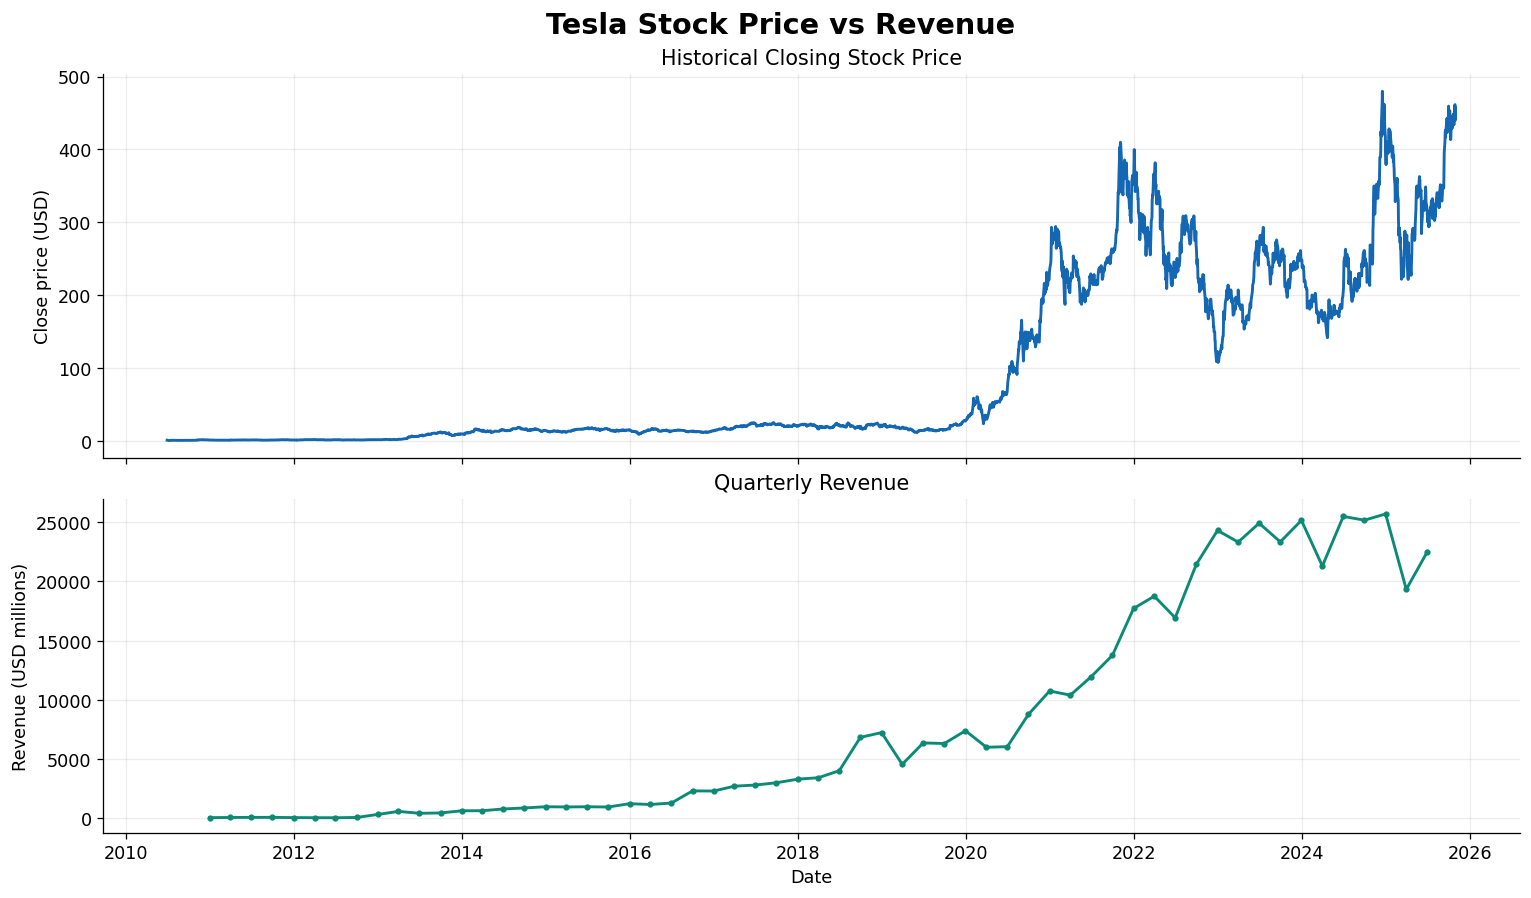

In [8]:
# Question 5 — Tesla stock price and quarterly revenue dashboard
fig_tesla = make_graph(tesla_data, tesla_revenue,
                       "Tesla Stock Price vs Revenue",
                       "Question_5_Tesla_Stock_and_Revenue_Graph.png")

## Question 6: Plot GameStop Stock Graph
Call `make_graph` with the GME stock and revenue DataFrames, with a descriptive title.

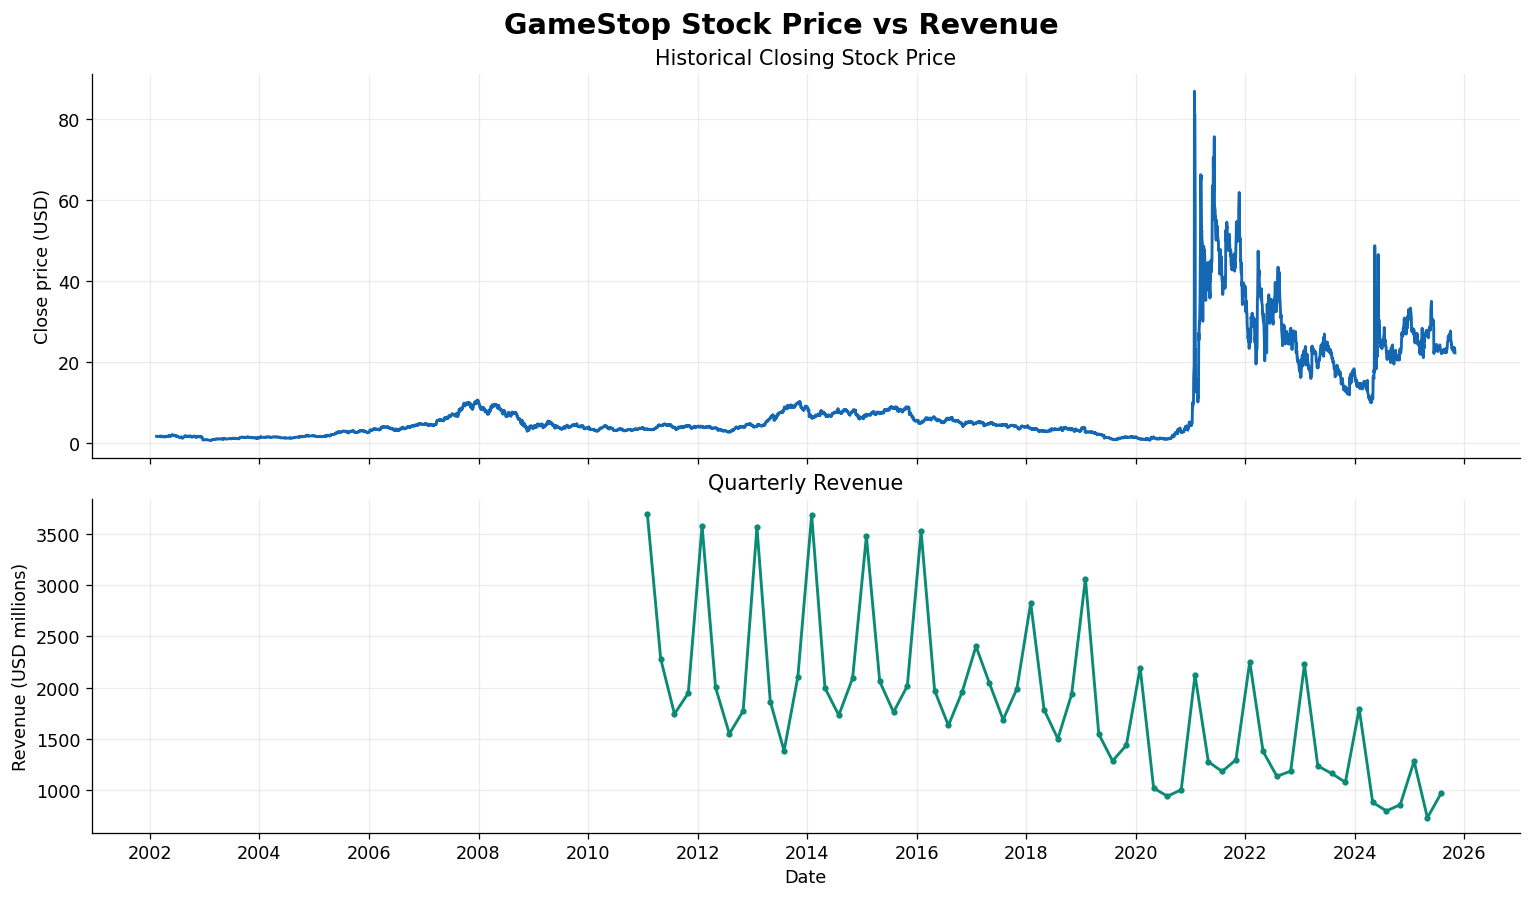

In [9]:
# Question 6 — GameStop stock price and quarterly revenue dashboard
fig_gme = make_graph(gme_data, gme_revenue,
                     "GameStop Stock Price vs Revenue",
                     "Question_6_GameStop_Stock_and_Revenue_Graph.png")

## Question 7: Share Your Assignment Notebook
Upload this `.ipynb` file and the `data/` folder to **your own GitHub repository**, then paste the actual URL into Coursera. Do not submit another person's notebook URL.

**Data sources**: yfinance historic prices and GitHub archived revenue tables: https://github.com/filipe-braiman/stock-data-extraction-visualization/tree/master/Datasets. Revenue amounts are in USD millions; cached historical data is not a current market quote.